In [1]:
from pathlib import Path
import gzip
import hashlib
import json
import platform
import random
import struct
import time
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import joblib
from threadpoolctl import threadpool_limits
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score, log_loss

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "requirements.txt").exists() and (p / "notebooks").is_dir())
RAW = ROOT / "data" / "raw"
SPLITS = ROOT / "data" / "splits"
RESULTS = ROOT / "results" / "validation-comparison"
RESULTS.mkdir(parents=True, exist_ok=True)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
CLASS_NAMES = np.array(["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"])
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
environment = {"python": platform.python_version(), "device": str(DEVICE), **{name: version(name) for name in ("numpy", "pandas", "scikit-learn", "torch")}}
display(pd.Series(environment, name="Environment"))

python          3.12.0
device             mps
numpy            2.5.4
pandas           3.0.6
scikit-learn     1.9.1
torch           2.14.1
Name: Environment, dtype: str

In [2]:
def read_idx(path):
    with gzip.open(path, "rb") as stream:
        payload = stream.read()
    zero_a, zero_b, dtype_code, dimensions = struct.unpack(">BBBB", payload[:4])
    if (zero_a, zero_b, dtype_code) != (0, 0, 8) or dimensions not in (1, 3):
        raise ValueError(f"Invalid IDX header: {path.name}")
    offset = 4 + 4 * dimensions
    shape = struct.unpack(">" + "I" * dimensions, payload[4:offset])
    values = np.frombuffer(payload, dtype=np.uint8, offset=offset)
    if values.size != np.prod(shape):
        raise ValueError(f"Invalid IDX payload size: {path.name}")
    return values.reshape(shape)

metadata_path = SPLITS / "train-validation-v1.json"
split_path = SPLITS / "train-validation-v1.npz"
if not metadata_path.exists() or not split_path.exists():
    raise FileNotFoundError("Run 01-data-exploration.ipynb first")
split_metadata = json.loads(metadata_path.read_text())
split_sha256 = hashlib.sha256(split_path.read_bytes()).hexdigest()
assert split_sha256 == split_metadata["split_file_sha256"]
training_files = [record for record in split_metadata["files"] if record["filename"].startswith("train-")]
for record in training_files:
    assert hashlib.sha256((RAW / record["filename"]).read_bytes()).hexdigest() == record["sha256"]
images = read_idx(RAW / "train-images-idx3-ubyte.gz")
labels = read_idx(RAW / "train-labels-idx1-ubyte.gz")
with np.load(split_path, allow_pickle=False) as saved:
    train_indices = saved["train_indices"]
    validation_indices = saved["validation_indices"]
assert images.shape == (60000, 28, 28) and labels.shape == (60000,)
assert np.array_equal(np.sort(np.concatenate([train_indices, validation_indices])), np.arange(len(labels)))
assert np.intersect1d(train_indices, validation_indices).size == 0
X_train = torch.from_numpy(images[train_indices].astype(np.float32) / 255.0).unsqueeze(1)
X_validation = torch.from_numpy(images[validation_indices].astype(np.float32) / 255.0).unsqueeze(1)
y_train = labels[train_indices]
y_validation = labels[validation_indices]
train_dataset = TensorDataset(X_train, torch.from_numpy(y_train.astype(np.int64)))
validation_dataset = TensorDataset(X_validation, torch.from_numpy(y_validation.astype(np.int64)))
BATCH_SIZE = 128
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, generator=torch.Generator().manual_seed(SEED))
train_eval_loader = DataLoader(train_dataset, batch_size=512, shuffle=False, num_workers=0)
validation_loader = DataLoader(validation_dataset, batch_size=512, shuffle=False, num_workers=0)
assert tuple(X_train.shape) == (48000, 1, 28, 28)
assert tuple(X_validation.shape) == (12000, 1, 28, 28)
assert torch.isfinite(X_train).all() and torch.isfinite(X_validation).all()
assert 0 <= X_train.min() <= X_train.max() <= 1
assert 0 <= X_validation.min() <= X_validation.max() <= 1
display(pd.DataFrame({"split": ["Training", "Validation"], "shape": [str(tuple(X_train.shape)), str(tuple(X_validation.shape))]}))

,split,shape
0,Training,"(48000, 1, 28, 28)"
1,Validation,"(12000, 1, 28, 28)"


In [3]:
MODEL_FILES = {
    "Logistic regression": ("logistic-regression-regularization", "selected-validation-predictions.csv"),
    "kNN": ("knn-comparison", "selected-validation-predictions.csv"),
    "CNN": ("cnn-improvements", "validation-predictions.csv"),
}
metadata_by_model = {}
predictions_by_model = {}
source_records = []
for name, (folder, filename) in MODEL_FILES.items():
    directory = ROOT / "results" / folder
    metadata_path = directory / "run-metadata.json"
    metadata = json.loads(metadata_path.read_text())
    assert metadata["split_sha256"] == split_sha256
    table = pd.read_csv(directory / filename)
    assert table.source_index.is_unique
    assert len(table) == len(validation_indices)
    assert set(table.source_index) == set(validation_indices)
    table = table.set_index("source_index").loc[validation_indices]
    np.testing.assert_array_equal(table.actual.to_numpy(), y_validation)
    assert np.isin(table.predicted.to_numpy(), np.arange(10)).all()
    predictions_by_model[name] = table.predicted.to_numpy()
    metadata_by_model[name] = metadata
    source_records.append({"model": name, "predictions_path": str((directory / filename).relative_to(ROOT)),
                           "predictions_sha256": hashlib.sha256((directory / filename).read_bytes()).hexdigest(),
                           "metadata_sha256": hashlib.sha256(metadata_path.read_bytes()).hexdigest()})
assert metadata_by_model["Logistic regression"]["selected_C"] == 0.1
assert metadata_by_model["kNN"]["selected_k"] == 3
assert metadata_by_model["CNN"]["selected_name"] == "wider"
metric_rows = []
recall_by_model = {}
confusion_rows = []
for name, predictions in predictions_by_model.items():
    report = classification_report(y_validation, predictions, labels=np.arange(10), output_dict=True, zero_division=0)
    metric_rows.append({"model": name, "correct": int((predictions == y_validation).sum()),
                       "errors": int((predictions != y_validation).sum()), "accuracy": accuracy_score(y_validation, predictions),
                       "macro_f1": f1_score(y_validation, predictions, average="macro"), "shirt_recall": report["6"]["recall"]})
    recall_by_model[name] = [report[str(i)]["recall"] for i in range(10)]
    matrix = confusion_matrix(y_validation, predictions, labels=np.arange(10))
    for i in range(10):
        for j in range(10):
            if i != j and matrix[i,j] > 0:
                confusion_rows.append({"model": name, "actual": CLASS_NAMES[i], "predicted": CLASS_NAMES[j], "images": int(matrix[i,j])})
metrics_table = pd.DataFrame(metric_rows).set_index("model")
recall_table = pd.DataFrame(recall_by_model, index=CLASS_NAMES)
confusions = pd.DataFrame(confusion_rows)
display(metrics_table.round(4))
display(recall_table.round(4))
display(confusions.sort_values("images", ascending=False).groupby("model", sort=False).head(5))

,correct,errors,accuracy,macro_f1,shirt_recall
model,,,,,
Logistic regression,10248,1752,0.8540,0.8530,0.5942
kNN,10246,1754,0.8538,0.8534,0.5892
CNN,11080,920,0.9233,0.9225,0.7208


,Logistic regression,kNN,CNN
T-shirt/top,0.8000,0.8433,0.8800
Trouser,0.9725,0.9775,0.9900
Pullover,0.7592,0.8133,0.9167
Dress,0.8825,0.8600,0.9267
Coat,0.7933,0.7575,0.9017
Sandal,0.9258,0.8425,0.9775
Shirt,0.5942,0.5892,0.7208
Sneaker,0.9208,0.9342,0.9608
Bag,0.9542,0.9592,0.9900
Ankle boot,0.9375,0.9617,0.9692


,model,actual,predicted,images
94,kNN,Shirt,T-shirt/top,212
37,Logistic regression,Shirt,T-shirt/top,171
96,kNN,Shirt,Pullover,169
83,kNN,Coat,Pullover,158
15,Logistic regression,Pullover,Coat,143
39,Logistic regression,Shirt,Pullover,142
150,CNN,Shirt,T-shirt/top,142
64,kNN,T-shirt/top,Shirt,127
5,Logistic regression,T-shirt/top,Shirt,122
26,Logistic regression,Coat,Pullover,108


,seeds,accuracy_mean,accuracy_std,macro_f1_mean,shirt_recall_mean
name,,,,,
wider,3,0.92400,0.00347,0.92358,0.75806
wider_weight_decay,3,0.92339,0.00059,0.92331,0.78944


CNN seed-summary values are means/sample SD across three runs; primary tables use individual seed-42 checkpoints.


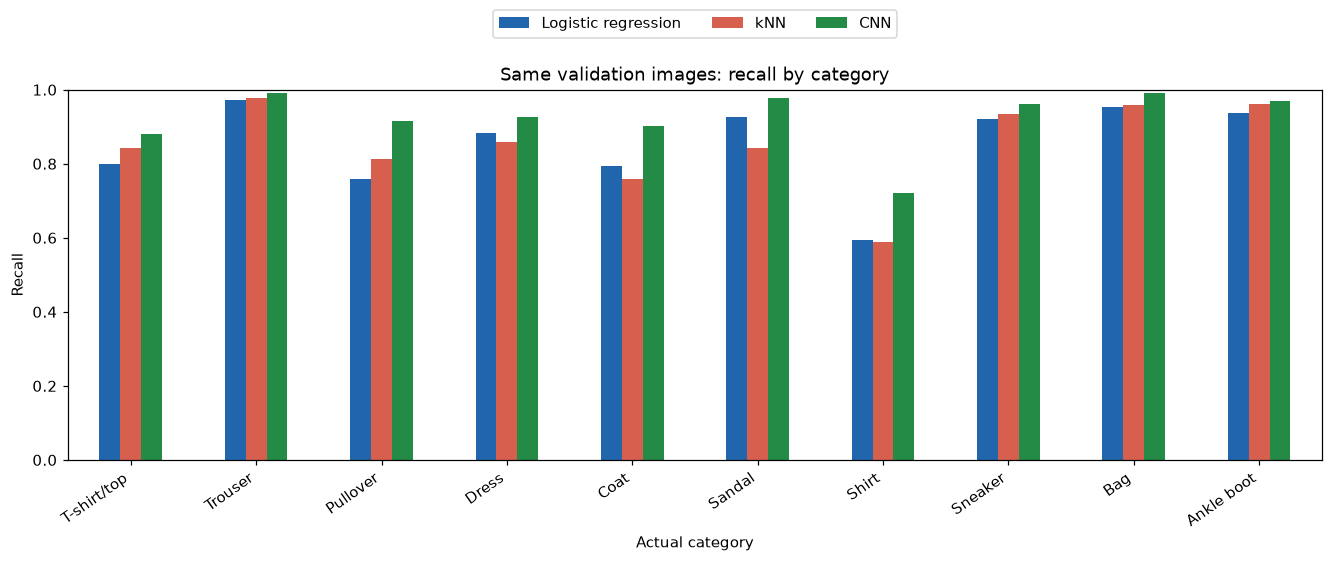

In [4]:
stability_path = ROOT / "results" / "cnn-stability" / "run-metadata.json"
stability_metadata = json.loads(stability_path.read_text())
assert stability_metadata["split_sha256"] == split_sha256
stability_summary = pd.DataFrame(stability_metadata["summary"]).set_index("name")
display(stability_summary[["seeds", "accuracy_mean", "accuracy_std", "macro_f1_mean", "shirt_recall_mean"]].round(5))
print("CNN seed-summary values are means/sample SD across three runs; primary tables use individual seed-42 checkpoints.")
fig, ax = plt.subplots(figsize=(12, 5), layout="constrained")
recall_table.plot.bar(ax=ax, color=["#2166ac", "#d6604d", "#238b45"])
ax.set(title="Same validation images: recall by category", xlabel="Actual category", ylabel="Recall", ylim=(0,1))
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.12), ncol=3)
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
fig.savefig(RESULTS / "class-recall-comparison.png", bbox_inches="tight")
plt.show()

,Logistic regression,kNN,CNN,images
0,True,True,True,9333
1,True,False,True,672
2,False,True,True,636
3,False,False,False,511
4,False,False,True,439
5,False,True,False,166
6,True,False,False,132
7,True,True,False,111


,first_model,second_model,both_correct,both_wrong,first_correct_second_wrong,second_correct_first_wrong
0,Logistic regression,kNN,9444,950,804,802
1,Logistic regression,CNN,10005,677,243,1075
2,kNN,CNN,9969,643,277,1111


,group,images
0,All three wrong,511
1,CNN correct; both classical wrong,439
2,CNN wrong; both classical correct,111


All three correct: 9333
All three wrong with the same predicted label: 346


Shirt          197
T-shirt/top     77
Pullover        62
Coat            61
Dress           42
Sandal          22
Sneaker         18
Ankle boot      18
Trouser          7
Bag              7
Name: All-model errors, dtype: int64

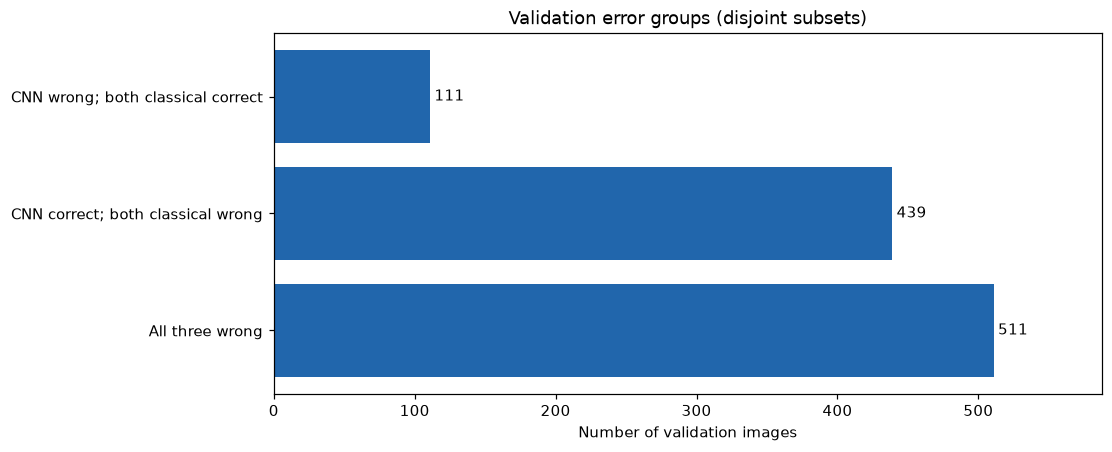

In [5]:
names = list(predictions_by_model)
correct = pd.DataFrame({name: pred == y_validation for name, pred in predictions_by_model.items()})
patterns = correct.value_counts().reset_index(name="images")
display(patterns)
pairwise_rows = []
for i, first in enumerate(names):
    for second in names[i+1:]:
        first_ok, second_ok = correct[first].to_numpy(), correct[second].to_numpy()
        pairwise_rows.append({"first_model": first, "second_model": second,
            "both_correct": int((first_ok & second_ok).sum()), "both_wrong": int((~first_ok & ~second_ok).sum()),
            "first_correct_second_wrong": int((first_ok & ~second_ok).sum()),
            "second_correct_first_wrong": int((~first_ok & second_ok).sum())})
pairwise = pd.DataFrame(pairwise_rows)
assert (pairwise.iloc[:,2:].sum(axis=1) == len(y_validation)).all()
display(pairwise)
GROUPS = {
    "All three wrong": (~correct.any(axis=1)).to_numpy(),
    "CNN correct; both classical wrong": (correct.CNN & ~correct["Logistic regression"] & ~correct.kNN).to_numpy(),
    "CNN wrong; both classical correct": (~correct.CNN & correct["Logistic regression"] & correct.kNN).to_numpy(),
}
error_groups = pd.DataFrame({"group": list(GROUPS), "images": [int(mask.sum()) for mask in GROUPS.values()]})
display(error_groups)
all_wrong = GROUPS["All three wrong"]
shared_wrong_labels = all_wrong & (predictions_by_model["CNN"] == predictions_by_model["kNN"]) & (predictions_by_model["CNN"] == predictions_by_model["Logistic regression"])
print("All three correct:", int(correct.all(axis=1).sum()))
print("All three wrong with the same predicted label:", int(shared_wrong_labels.sum()))
shared_by_class = pd.Series(CLASS_NAMES[y_validation[all_wrong]]).value_counts().rename("All-model errors")
display(shared_by_class)
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
ax.barh(error_groups.group, error_groups.images, color="#2166ac")
ax.set(xlabel="Number of validation images", title="Validation error groups (disjoint subsets)")
for position, value in enumerate(error_groups.images):
    ax.text(value + 3, position, str(value), va="center")
ax.set_xlim(0, max(error_groups.images.max() * 1.15, 1))
fig.savefig(RESULTS / "error-groups.png", bbox_inches="tight")
plt.show()

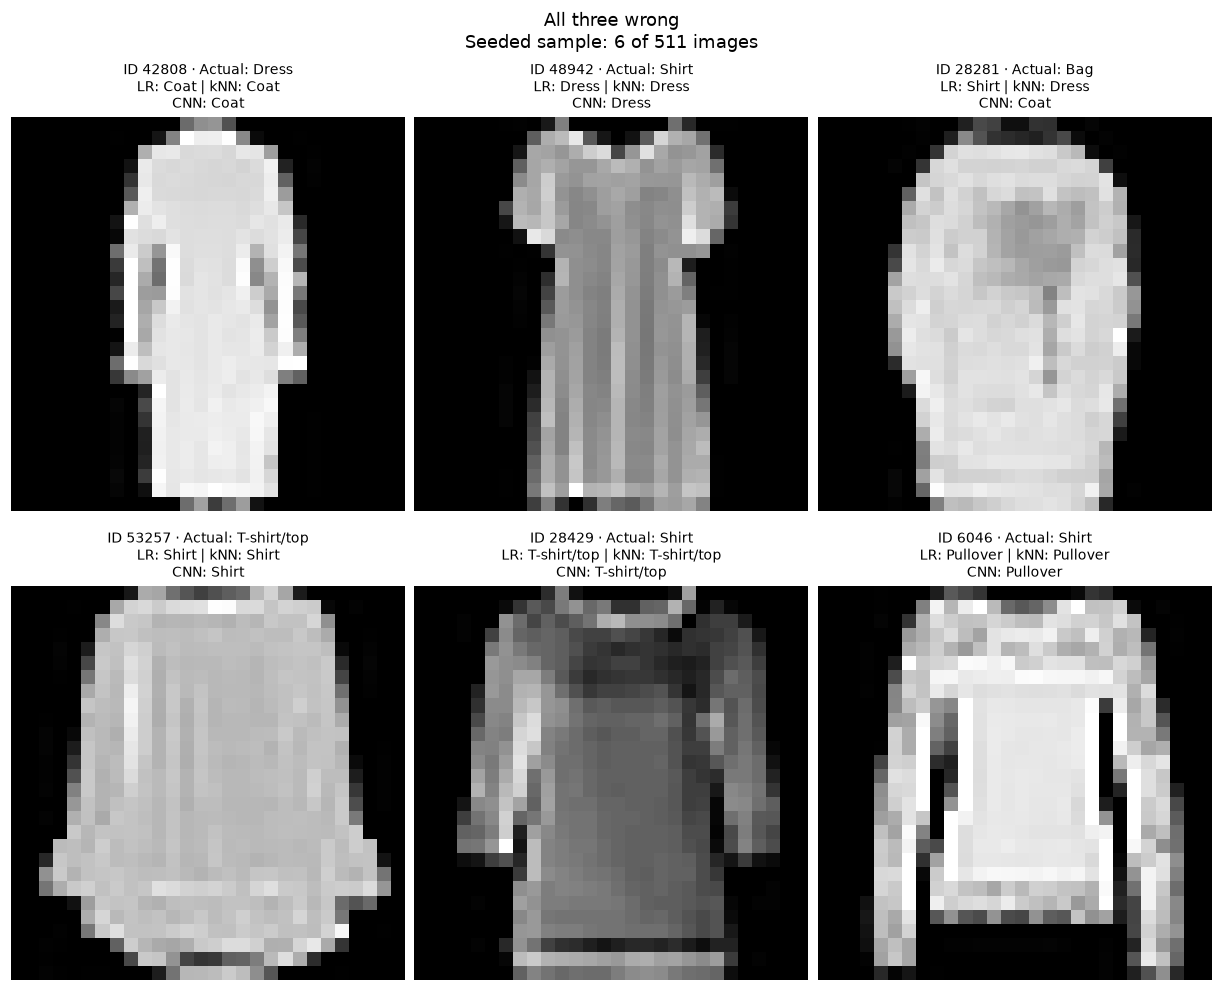

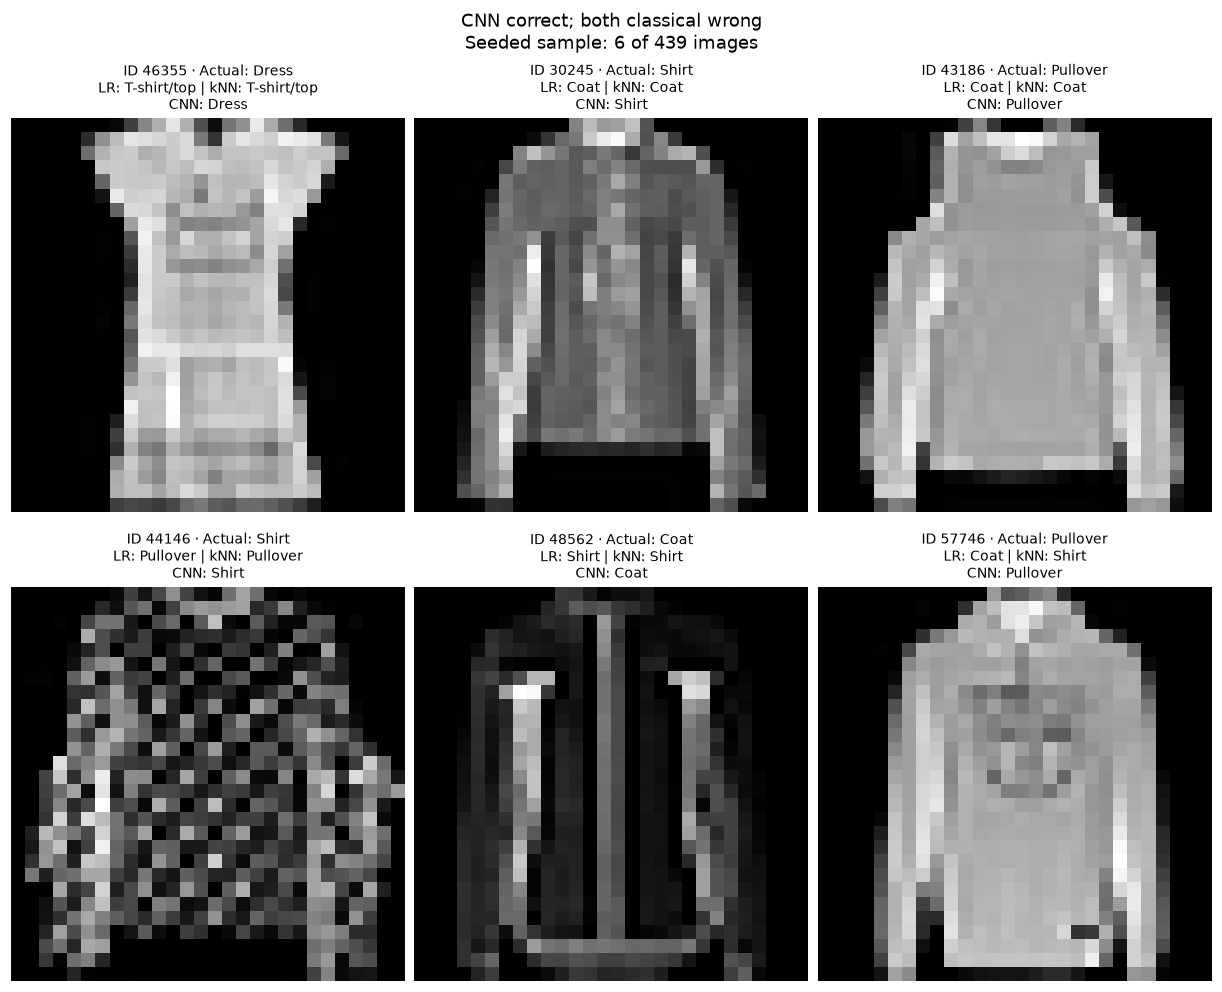

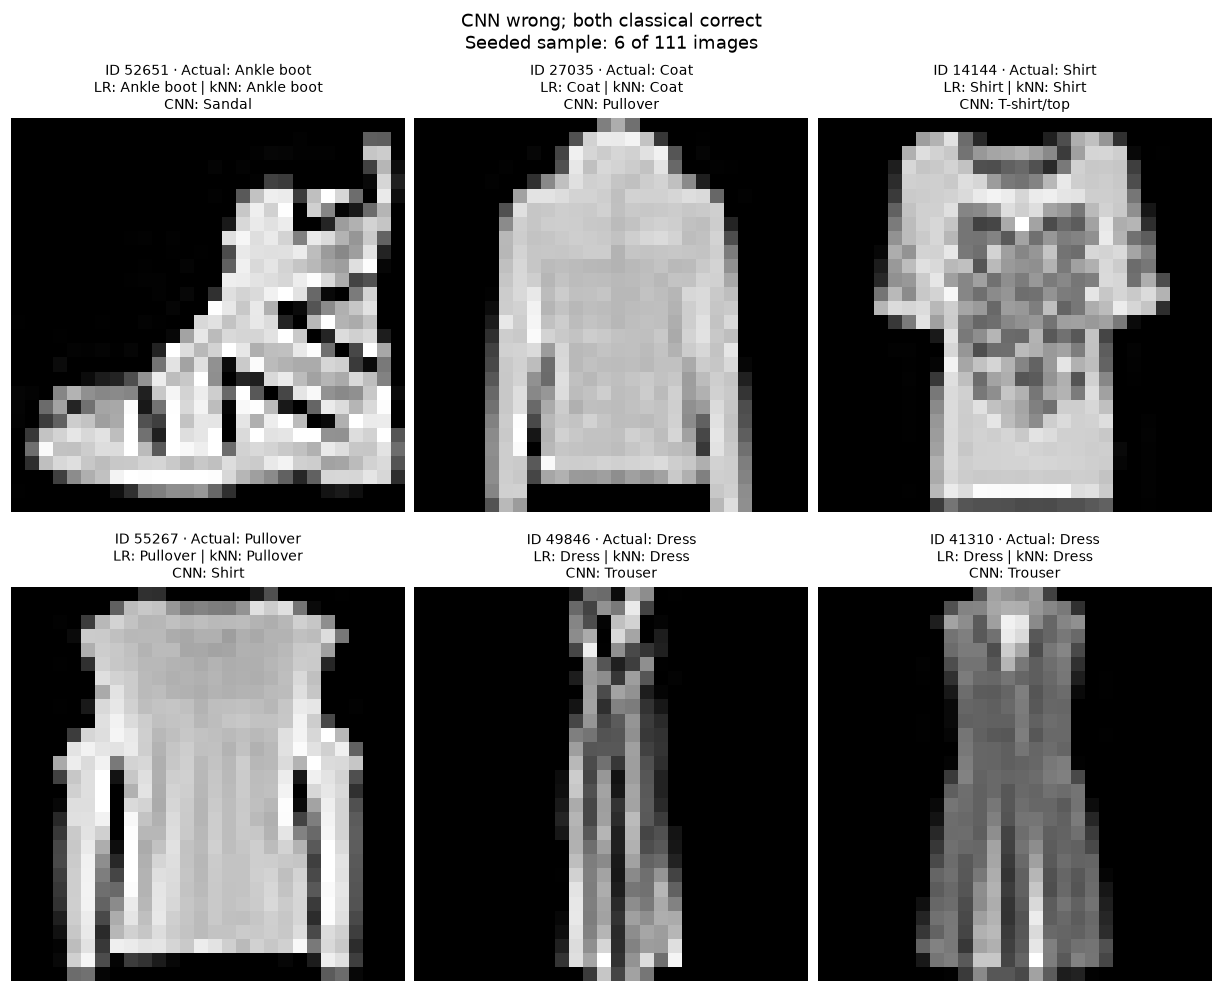

In [6]:
rng = np.random.default_rng(SEED)
sampled_examples = []
for group_number, (group_name, mask) in enumerate(GROUPS.items(), start=1):
    positions = np.flatnonzero(mask)
    selected = rng.choice(positions, size=min(6, len(positions)), replace=False)
    fig, axes = plt.subplots(2, 3, figsize=(11, 9), layout="constrained")
    for ax in axes.ravel():
        ax.axis("off")
    for ax, position in zip(axes.ravel(), selected):
        ax.imshow(images[validation_indices[position]], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"ID {validation_indices[position]} · Actual: {CLASS_NAMES[y_validation[position]]}\nLR: {CLASS_NAMES[predictions_by_model['Logistic regression'][position]]} | kNN: {CLASS_NAMES[predictions_by_model['kNN'][position]]}\nCNN: {CLASS_NAMES[predictions_by_model['CNN'][position]]}", fontsize=9)
        sampled_examples.append({"group": group_name, "source_index": int(validation_indices[position]), "actual": int(y_validation[position]),
                                 **{name: int(pred[position]) for name, pred in predictions_by_model.items()}})
    fig.suptitle(f"{group_name}\nSeeded sample: {len(selected)} of {len(positions)} images")
    fig.savefig(RESULTS / f"error-examples-{group_number}.png", bbox_inches="tight")
    plt.show()

In [7]:
def build_cnn(config):
    first, second = config["channels"]
    return nn.Sequential(
        nn.Conv2d(1, first, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(first, second, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(), nn.Linear(second * 7 * 7, config["hidden"]), nn.ReLU(), nn.Dropout(0.25), nn.Linear(config["hidden"], 10),
    )

model_paths = {
    "Logistic regression": ROOT / "results/logistic-regression-regularization/selected-model.joblib",
    "kNN": ROOT / "results/knn-comparison/selected-model.joblib",
    "CNN": ROOT / "results/cnn-improvements/selected-model.pt",
}
for name, path in model_paths.items():
    checksum_key = "selected_checkpoint_sha256" if name == "CNN" else "model_sha256"
    assert hashlib.sha256(path.read_bytes()).hexdigest() == metadata_by_model[name][checksum_key]
classical_models = {name: joblib.load(model_paths[name]) for name in names if name != "CNN"}
cnn_cpu = build_cnn(metadata_by_model["CNN"]["selected_config"]).cpu()
cnn_cpu.load_state_dict(torch.load(model_paths["CNN"], map_location="cpu", weights_only=True))
cnn_cpu.eval()
X_validation_classical = images[validation_indices].reshape(len(validation_indices), -1).astype(np.float64) / 255.0
X_validation_cpu = X_validation.cpu()
TIMING_BATCH_SIZE = 256
TIMING_REPEATS = 3
torch.set_num_threads(4)

@torch.inference_mode()
def predict_cpu(name, stop):
    chunks = []
    for start in range(0, stop, TIMING_BATCH_SIZE):
        end = min(start + TIMING_BATCH_SIZE, stop)
        if name == "CNN":
            chunks.append(cnn_cpu(X_validation_cpu[start:end]).argmax(dim=1).numpy())
        else:
            chunks.append(classical_models[name].predict(X_validation_classical[start:end]))
    return np.concatenate(chunks)

timing_rows = []
with threadpool_limits(limits=4):
    for name in names:
        predict_cpu(name, TIMING_BATCH_SIZE)
    for repeat in range(TIMING_REPEATS):
        order = names[repeat:] + names[:repeat]
        for name in order:
            start = time.perf_counter()
            cpu_predictions = predict_cpu(name, len(y_validation))
            seconds = time.perf_counter() - start
            timing_rows.append({"repeat": repeat + 1, "model": name, "seconds": seconds,
                                "prediction_disagreements_with_saved": int((cpu_predictions != predictions_by_model[name]).sum())})
timings = pd.DataFrame(timing_rows)
timing_summary = timings.groupby("model").agg(median_seconds=("seconds", "median"), min_seconds=("seconds", "min"), max_seconds=("seconds", "max"), max_prediction_disagreements=("prediction_disagreements_with_saved", "max"))
timing_summary["images_per_second"] = len(y_validation) / timing_summary.median_seconds
timing_summary["saved_model_bytes"] = pd.Series({name: path.stat().st_size for name, path in model_paths.items()})
display(timing_summary.round(4))
print("CPU only; 4 computational threads; batches of 256; 12,000 images; loading/preprocessing excluded")
print("Saved artifact sizes use different serialization/compression formats and are not RAM measurements")

,median_seconds,min_seconds,max_seconds,max_prediction_disagreements,images_per_second,saved_model_bytes
model,,,,,,
CNN,0.6754,0.6564,0.6950,0,1.776825e+04,1690031
Logistic regression,0.0056,0.0054,0.0063,0,2.155656e+06,63671
kNN,2.6699,2.6154,2.9493,0,4.494597e+03,37475216


CPU only; 4 computational threads; batches of 256; 12,000 images; loading/preprocessing excluded
Saved artifact sizes use different serialization/compression formats and are not RAM measurements


In [8]:
metrics_table.to_csv(RESULTS / "validation-metrics.csv")
recall_table.to_csv(RESULTS / "class-recall.csv")
confusions.to_csv(RESULTS / "confusions.csv", index=False)
patterns.to_csv(RESULTS / "correctness-patterns.csv", index=False)
pairwise.to_csv(RESULTS / "paired-errors.csv", index=False)
error_groups.to_csv(RESULTS / "error-groups.csv", index=False)
shared_by_class.to_csv(RESULTS / "shared-errors-by-class.csv")
pd.DataFrame(sampled_examples).to_csv(RESULTS / "sampled-error-examples.csv", index=False)
timings.to_csv(RESULTS / "timing-repeats.csv", index=False)
timing_summary.to_csv(RESULTS / "timing-summary.csv")
joined = pd.DataFrame({"source_index": validation_indices, "actual": y_validation, **predictions_by_model})
joined.to_csv(RESULTS / "aligned-validation-predictions.csv", index=False)
metadata = {"split_sha256": split_sha256, "source_files": training_files, "prediction_sources": source_records,
            "stability_metadata_sha256": hashlib.sha256(stability_path.read_bytes()).hexdigest(),
            "environment": environment, "cnn_selection": metadata_by_model["CNN"]["selected_name"],
            "cnn_prediction_seed": metadata_by_model["CNN"]["seed"], "validation_count": len(y_validation), "test_evaluated": False,
            "metrics": metrics_table.reset_index().to_dict(orient="records"), "pairwise": pairwise_rows,
            "all_three_correct": int(correct.all(axis=1).sum()), "shared_errors_same_prediction": int(shared_wrong_labels.sum()),
            "error_groups": error_groups.to_dict(orient="records"),
            "timing": {"device": "cpu", "threads": 4, "batch_size": TIMING_BATCH_SIZE, "repeats": TIMING_REPEATS,
                       "warmup_images_per_model": TIMING_BATCH_SIZE, "order": "rotated", "includes_loading_or_preprocessing": False,
                       "summary": timing_summary.reset_index().to_dict(orient="records")}}
(RESULTS / "run-metadata.json").write_text(json.dumps(metadata, indent=2) + "\n")
print("Saved results/validation-comparison artifacts")

Saved results/validation-comparison artifacts
